# 3. Heat, and why protection needs error correction

Here the torus is coupled to a heat bath at temperature $T$. Each sweep, every edge gets on average one attempted
random $X$ or $Z$, accepted with probability $\min(1, e^{-\Delta E/T})$ (Metropolis). Creating a pair costs
$\Delta E = +4$; moving an anyon ($\Delta E = 0$) or annihilating a pair ($\Delta E = -4$) always happens. The state
stays a Pauli string times the start state, so this simulation of Pauli noise is exact.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import toric

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.figsize": (5.5, 3.4)})

RESULTS = Path("../results")
rng = np.random.default_rng(0)

## Equilibrium: heat keeps some anyons around

The second law does not drive the system to zero energy; it minimizes the free energy $F = E - TS$. In the Gibbs
state every stabilizer is independently $-1$ with probability $1/(1 + e^{2/T})$ (up to the rule that anyons come
in pairs, which hardly matters on a large torus). Live run on a $6 \times 6$ torus:

In [2]:
s = toric.new_state(6)
fractions = []
for sweep in range(400):
    toric.thermal_sweep(s, 1.0, rng)
    if sweep >= 100:
        fractions.append((s.e_flags.sum() + s.m_flags.sum()) / 72)
print(f"T = 1: fraction of stabilizers at -1 = {np.mean(fractions):.3f}, Gibbs value = {1 / (1 + np.exp(2)):.3f}")

T = 1: fraction of stabilizers at -1 = 0.117, Gibbs value = 0.119


Full run (`python scripts/make_results.py equilibrium`, under a minute):

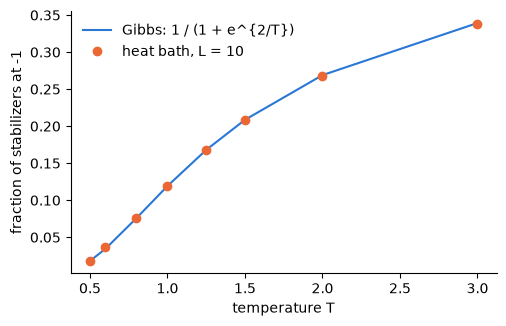

In [3]:
eq = json.loads((RESULTS / "equilibrium.json").read_text())
T = [p["T"] for p in eq["points"]]
plt.plot(T, [p["gibbs"] for p in eq["points"]], color=BLUE, label="Gibbs: 1 / (1 + e^{2/T})")
plt.plot(T, [p["fraction"] for p in eq["points"]], "o", color=ORANGE, label=f"heat bath, L = {eq['L']}")
plt.xlabel("temperature T")
plt.ylabel("fraction of stabilizers at -1")
plt.legend(frameon=False);

## A lone pair does not simply annihilate

A fresh pair starts as neighbours, and annihilating is downhill, so many pairs vanish at once. But once the two
anyons are one step apart, **nothing pulls them back**: the energy is $+4$ whatever their separation, because the
string between them costs nothing. Each anyon is then a free random walker. Live: 500 pairs on a $20 \times 20$
torus at $T \to 0$ (no new pairs).

In [4]:
runs = [toric.single_pair(20, rng) for _ in range(500)]
quick = np.mean([dead and t <= 1 for t, _, dead in runs])
far = np.mean([sep >= 10 for _, sep, _ in runs])
print(f"annihilated within 1 sweep: {quick:.0%}   drifted L/2 = 10 or more apart at some point: {far:.0%}")

annihilated within 1 sweep: 16%   drifted L/2 = 10 or more apart at some point: 63%


Full run (`python scripts/make_results.py single_pair`, about a minute):

20000 pairs on a 20 x 20 torus
  annihilated within    1 sweeps: 19.3%
  annihilated within   10 sweeps: 35.6%
  annihilated within  100 sweeps: 53.7%
  annihilated within 1000 sweeps: 97.4%
  reached L/2 apart: 60.0%


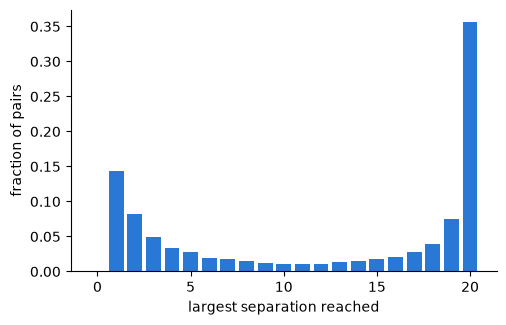

In [5]:
sp = json.loads((RESULTS / "single_pair.json").read_text())
print(f"{sp['runs']} pairs on a {sp['L']} x {sp['L']} torus")
for k, f in sp["annihilated_within"].items():
    print(f"  annihilated within {k:>4} sweeps: {f:.1%}")
print(f"  reached L/2 apart: {sp['reached_half_L']:.1%}")
hist = np.array(sp["max_separation_histogram"])
plt.bar(np.arange(len(hist)), hist / hist.sum(), color=BLUE)
plt.xlabel("largest separation reached")
plt.ylabel("fraction of pairs");

That freedom is what scrambles the memory: a pair that wanders around the torus and meets again has applied a
logical operator. Entropy even favours separation, since there are many more ways to be far apart than close.

## Memory lifetime, without and with correction

*Correct every sweep* measures all stabilizers after each sweep, pairs the closest anyons (greedy decoder) and joins
each pair by a shortest string. A logical error then needs a pair to drift about $L/2$ apart within one sweep.
Live run, 10 runs per point:

In [6]:
for L in (4, 6, 8):
    out = []
    for every in (None, 1):
        out.append(np.mean([toric.memory_lifetime(L, 0.6, every, 2000, rng) for _ in range(10)]))
    print(f"L = {L}: no correction {out[0]:6.0f} sweeps | correct every sweep {out[1]:6.0f} sweeps")

L = 4: no correction     28 sweeps | correct every sweep    126 sweeps
L = 6: no correction     21 sweeps | correct every sweep    315 sweeps


L = 8: no correction     15 sweeps | correct every sweep    573 sweeps


Full run (`python scripts/make_results.py memory_lifetimes`, a few minutes on 4 cores):

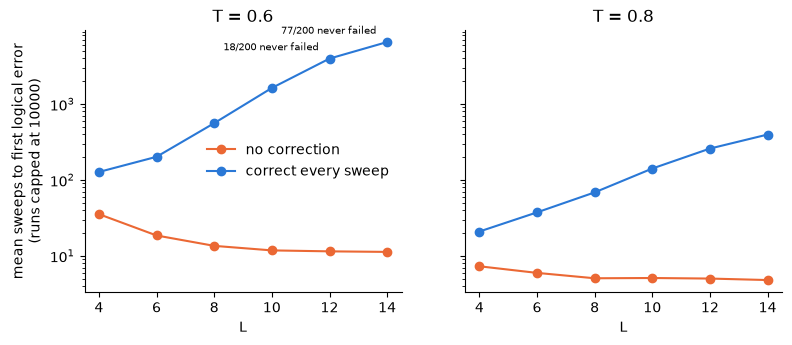

In [7]:
ml = json.loads((RESULTS / "memory_lifetimes.json").read_text())
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, T in zip(axes, sorted({p["T"] for p in ml["points"]}), strict=True):
    for every, color, label in [(None, ORANGE, "no correction"), (1, BLUE, "correct every sweep")]:
        pts = [p for p in ml["points"] if p["T"] == T and p["correct_every"] == every]
        ax.semilogy([p["L"] for p in pts], [p["mean"] for p in pts], "o-", color=color, label=label)
        for p in pts:
            if p["capped"]:
                ax.annotate(f"{p['capped']}/{ml['runs']} never failed", (p["L"], p["mean"]), fontsize=7,
                            xytext=(-8, 6), textcoords="offset points", ha="right")
    ax.set_title(f"T = {T}")
    ax.set_xlabel("L")
axes[0].set_ylabel(f"mean sweeps to first logical error\n(runs capped at {ml['max_sweeps']})")
axes[0].legend(frameon=False);

Without correction a bigger torus does **not** help: the memory time is set by $T$, and it even shrinks with $L$ (from
about 35 sweeps at $L = 4$ to 11 at $L = 14$) because there are more places for pairs to appear. With correction it grows rapidly with $L$.

The reason is the **energy barrier**. A logical error only ever costs the $+4$ of one pair, whatever $L$ is, so the
2D toric code is not a *self-correcting* memory. Its topology protects the qubits against small local
perturbations, and against heat only together with active error correction. A memory that protects itself at
$T > 0$ needs a barrier that grows with $L$, as in the 4D toric code, where errors are membranes rather than strings
(Dennis, Kitaev, Landahl, Preskill, [arXiv:quant-ph/0110143](https://arxiv.org/abs/quant-ph/0110143); Alicki,
Horodecki, Horodecki, Horodecki, [arXiv:0811.0033](https://arxiv.org/abs/0811.0033)).

## How often must you correct?

`memory_lifetime(L, T, correct_every=N, ...)` decodes only after every $N$-th sweep. Between corrections the anyons
keep wandering, so the advantage fades fast as $N$ grows. Full run (`python scripts/make_results.py
correction_interval`, a few minutes):

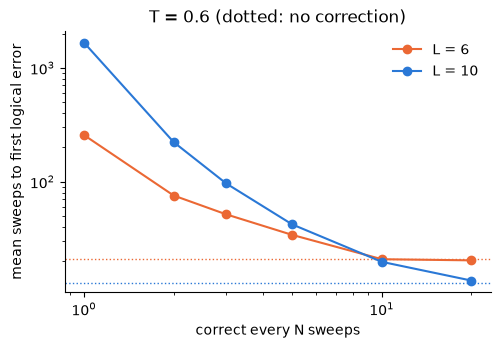

In [8]:
ci = json.loads((RESULTS / "correction_interval.json").read_text())
for L, color in [(6, ORANGE), (10, BLUE)]:
    pts = [p for p in ci["points"] if p["L"] == L and p["correct_every"]]
    never = next(p for p in ci["points"] if p["L"] == L and p["correct_every"] is None)
    plt.loglog([p["correct_every"] for p in pts], [p["mean"] for p in pts], "o-", color=color, label=f"L = {L}")
    plt.axhline(never["mean"], color=color, ls=":", lw=1)
plt.xlabel("correct every N sweeps")
plt.ylabel("mean sweeps to first logical error")
plt.title(f"T = {ci['T']} (dotted: no correction)")
plt.legend(frameon=False);

Frequent correction is what makes the bigger torus better: at $N = 1$ the $L = 10$ memory lasts several times longer
than $L = 6$. The advantage shrinks quickly with $N$, and between $N = 5$ and $10$ the curves cross: the bigger
torus is no better, even slightly worse, and both approach no correction at all. Correcting rarely is like not
correcting.

## Exercises

1. Rerun the live memory cell at `T = 0.8`. How does the ratio between the two columns change?
2. For $L = 8$, find the largest $N$ at which correcting still beats $L = 4$ corrected every sweep.
3. In `single_pair`, the energy does not depend on the separation. Change the rule so that each step away from the
   partner costs energy (a string tension). What happens to the largest separation reached?